# A classifier in depth: MNIST

The measures of [Evaluating a classifier](../classification_metrics.ipynb), applied to images of handwritten digits, and one question that only appears with more than two classes: how a classifier built to separate two classes handles ten. Adapted from chapter 3 of Aurélien Géron's *Hands-On Machine Learning* (sources at the end).

## The data

MNIST has 70,000 images of handwritten digits, each 28 × 28 pixels in grey levels. scikit-learn downloads it from [OpenML](https://www.openml.org/) the first time (about 15 MB). `as_frame=False` returns NumPy arrays: the 784 columns are the pixels in order, and their names would add nothing:

In [ ]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", as_frame=False)
X, y = mnist.data, mnist.target
X.shape, y.shape

((70000, 784), (70000,))

Each row is an image unrolled into 784 numbers from 0 (background) to 255 (ink). Rolled back into a 28 × 28 grid, it can be drawn:

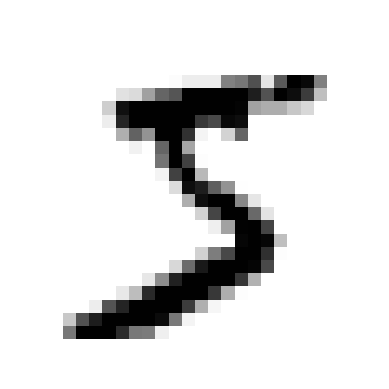

In [ ]:
import matplotlib.pyplot as plt


def plot_digit(image_data):
    plt.imshow(image_data.reshape(28, 28), cmap="binary")
    plt.axis("off")


some_digit = X[0]
plot_digit(some_digit)
plt.show()

In [ ]:
y[0]

'5'

The dataset comes with its own split: the first 60,000 images for training and the last 10,000 for testing. Using it, rather than a new random split, makes results comparable with everyone else's:

In [ ]:
X_train, X_test, y_train, y_test = X[:60_000], X[60_000:], y[:60_000], y[60_000:]

## A detector of fives

A binary problem first: is this digit a 5? The labels are strings, so the target is a comparison:

In [ ]:
y_train_5 = y_train == "5"
y_train_5.mean()

np.float64(0.09035)

`SGDClassifier` is a linear classifier trained by stochastic gradient descent; with its default settings, it is a linear support vector machine. [Gradient descent](../../ml-fundamentals/gradient_descent.ipynb) and [Support vector machines](../../deep-dives/svm.ipynb) explain both. Here it is just a fast classifier for 60,000 images, on pixels left unscaled because they already share one range, 0 to 255:

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd_classifier = SGDClassifier(random_state=42).fit(X_train, y_train_5)
sgd_classifier.predict([some_digit])

array([ True])

## Accuracy, and what to compare it with

The test set is kept for the end, so the classifier is measured with **cross-validation** on the training images: they are split into three parts, and three models are trained, each on two parts and measured on the third ([Cross-validation and hyperparameter search](../../ml-fundamentals/cross_validation_and_search.ipynb) explains it). The accuracy of each:

In [ ]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_classifier, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.95035, 0.96035, 0.9604 ])

And the classifier that answers "not a 5" to every image:

In [ ]:
from sklearn.dummy import DummyClassifier

cross_val_score(DummyClassifier(), X_train, y_train_5, cv=3, scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

About 95% to 96% correct in each fold. The classifier that never looks at an image is right 91% of the time, because 91% of the images are not fives. Measured against that, the detector's 95% is a modest gain, and the next section shows what it hides. A class much rarer than the rest is the subject of [When one class is rare](../imbalanced_classes.ipynb).

## Errors by kind

`cross_val_predict` returns, for every training image, the prediction of the model that didn't see it during cross-validation. With those predictions, a confusion matrix of the whole training set (its reading is in [Evaluating a classifier](../classification_metrics.ipynb#the-confusion-matrix)):

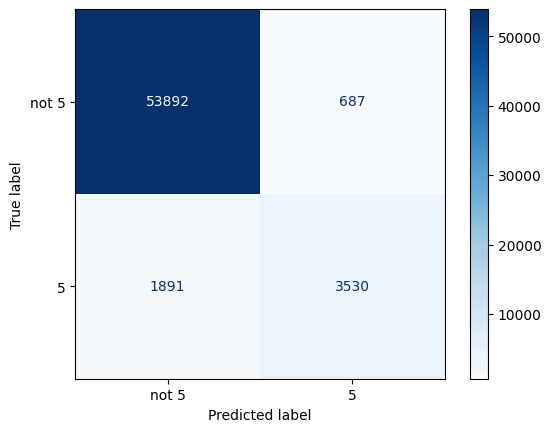

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

y_train_predicted = cross_val_predict(sgd_classifier, X_train, y_train_5, cv=3)
ConfusionMatrixDisplay.from_predictions(y_train_5, y_train_predicted, display_labels=["not 5", "5"], cmap="Blues")
plt.show()

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score

{
    "precision": precision_score(y_train_5, y_train_predicted),
    "recall": recall_score(y_train_5, y_train_predicted),
    "F1": f1_score(y_train_5, y_train_predicted),
}

{'precision': 0.8370879772350012,
 'recall': 0.6511713705958311,
 'F1': 0.7325171197343847}

When the detector says "5" it is right about 84% of the time (its precision), and of all the fives it finds about 65% (its recall): a third of the fives are missed, which the 95% accuracy didn't show. F1, 0.73, lies between the two and nearer the lower one, as a harmonic mean does. Which of the two matters more depends on what the detector is for, and moving its threshold exchanges one for the other, as in [Evaluating a classifier](../classification_metrics.ipynb#the-threshold).

## Ten classes from two

Some classifiers handle many classes directly: a tree, a forest, k-NN, or logistic regression with its softmax. Others can only separate two, support vector machines among them. Two strategies turn a binary classifier into one for ten classes:

- **One-vs-rest** (OvR): one binary classifier per class, each separating its class from all the others: ten classifiers for ten digits, like the 5-detector above. An image goes to the class whose classifier is most confident.
- **One-vs-one** (OvO): one binary classifier per *pair* of classes: 0 against 1, 0 against 2, ..., 8 against 9, which makes 10 × 9 / 2 = 45. An image goes to the class that wins most duels. Many more classifiers, but each is trained only on the images of its two classes.

scikit-learn applies one of them automatically when a binary classifier receives several classes: `SVC` uses one-vs-one, and `SGDClassifier` one-vs-rest. `OneVsRestClassifier` and `OneVsOneClassifier` force either. An `SVC` (with its default *kernel*, which lets it draw curved boundaries) on the first 2,000 training images:

In [ ]:
from sklearn.svm import SVC

svm_classifier = SVC().fit(X_train[:2_000], y_train[:2_000])
svm_classifier.predict([some_digit])

array(['5'], dtype=object)

The two strategies with the same `SVC`, each measured by cross-validation on the first 5,000 training images, with the time each takes to train (the times depend on the computer; their ratio is what matters):

In [ ]:
import time

import pandas as pd
from sklearn.multiclass import OneVsRestClassifier

strategies = {
    "SVC, one-vs-one (its default)": SVC(),
    "SVC, one-vs-rest": OneVsRestClassifier(SVC()),
}
comparison = {}
for name, classifier in strategies.items():
    start = time.perf_counter()
    scores = cross_val_score(classifier, X_train[:5_000], y_train[:5_000], cv=3, scoring="accuracy")
    comparison[name] = {"accuracy": scores.mean(), "seconds for 3 fits": time.perf_counter() - start}
pd.DataFrame(comparison).T.round(3)

,accuracy,seconds for 3 fits
"SVC, one-vs-one (its default)",0.944,2.253
"SVC, one-vs-rest",0.941,6.491


The two strategies reach about the same accuracy, 0.94, but one-vs-rest takes two to three times as long. Each of its ten classifiers is trained on all the images of a fold, while each of the 45 one-vs-one classifiers sees only the images of its two digits, about a fifth of them. Training an SVM costs more than proportionally to the number of images (between their square and their cube), so many small problems are cheaper than a few large ones: that is why `SVC` uses one-vs-one by default. For classifiers whose cost grows only in proportion to the data, such as `SGDClassifier`, scikit-learn uses one-vs-rest.

## Sources

- Aurélien Géron, [*Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*](https://www.oreilly.com/library/view/hands-on-machine-learning/9781098125967/), 3rd edition, chapter 3, *Classification*; the code is adapted from [its notebook](https://github.com/ageron/handson-ml3/blob/main/03_classification.ipynb) (Apache License 2.0)
- [scikit-learn user guide: multiclass and multioutput algorithms](https://scikit-learn.org/stable/modules/multiclass.html)